<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/02_light_ray_trajectories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os
import sys

repo_path = "/content/Blackhole_simulator_rayTracing"

if not os.path.exists(repo_path):
    %cd /content
    !git clone https://github.com/AnshG-19/Blackhole_simulator_rayTracing.git

os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("Repository connected:", os.getcwd())

Repository connected: /content/Blackhole_simulator_rayTracing


In [5]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from src.physics.ray_tracing import calculate_light_ray

M = 1.0
b = 8.0

ray = calculate_light_ray(
    mass_parameter=M,
    impact_parameter=b,
    max_angle=4.0,
    points=1500,
)

print(f"Mass parameter: {M}")
print(f"Impact parameter: {b}")
print(f"Closest approach: {ray['closest_approach']:.4f} M")
print(
    "Critical impact parameter: "
    f"{ray['critical_impact_parameter']:.4f} M"
)
print(f"Trajectory points: {len(ray['x'])}")

Mass parameter: 1.0
Impact parameter: 8.0
Closest approach: 6.7005 M
Critical impact parameter: 5.1962 M
Trajectory points: 1501


In [16]:
ray = calculate_light_ray(
    mass_parameter=M,
    impact_parameter=8.0,
    max_angle=2.6,
    points=2000,
)

print("Closest approach:", ray["closest_approach"])
print("Minimum plotted radius:", np.min(ray["radius"]))
print("Maximum plotted radius:", np.max(ray["radius"]))

Closest approach: 6.700523482266461
Minimum plotted radius: 6.700523482266461
Maximum plotted radius: 12.283100488407701


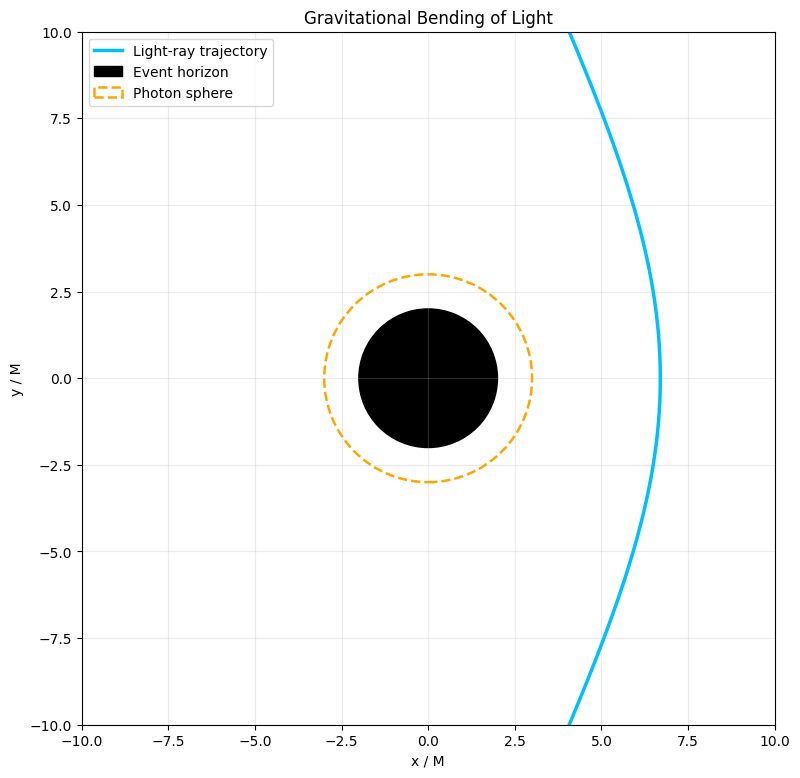

In [17]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.plot(
    ray["x"], ray["y"],
    color="deepskyblue",
    linewidth=2.5,
    label="Light-ray trajectory",
)

ax.add_patch(Circle((0, 0), 2 * M, color="black",
                    label="Event horizon"))
ax.add_patch(Circle((0, 0), 3 * M, fill=False,
                    color="orange", linestyle="--",
                    linewidth=1.8, label="Photon sphere"))

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Gravitational Bending of Light")
ax.grid(alpha=0.25)
ax.legend()

plt.show()

In [19]:
print("First 10 radii:")
print(np.round(ray["radius"][:10], 4))

print("\nRadii near closest approach:")
mid = len(ray["radius"]) // 2
print(np.round(ray["radius"][mid - 5:mid + 6], 4))

print("\nLast 10 radii:")
print(np.round(ray["radius"][-10:], 4))

First 10 radii:
[12.2831 12.2635 12.2439 12.2244 12.205  12.1856 12.1664 12.1472 12.1281
 12.109 ]

Radii near closest approach:
[6.7006 6.7006 6.7006 6.7005 6.7005 6.7005 6.7005 6.7005 6.7006 6.7006
 6.7006]

Last 10 radii:
[12.109  12.1281 12.1472 12.1664 12.1856 12.205  12.2244 12.2439 12.2635
 12.2831]


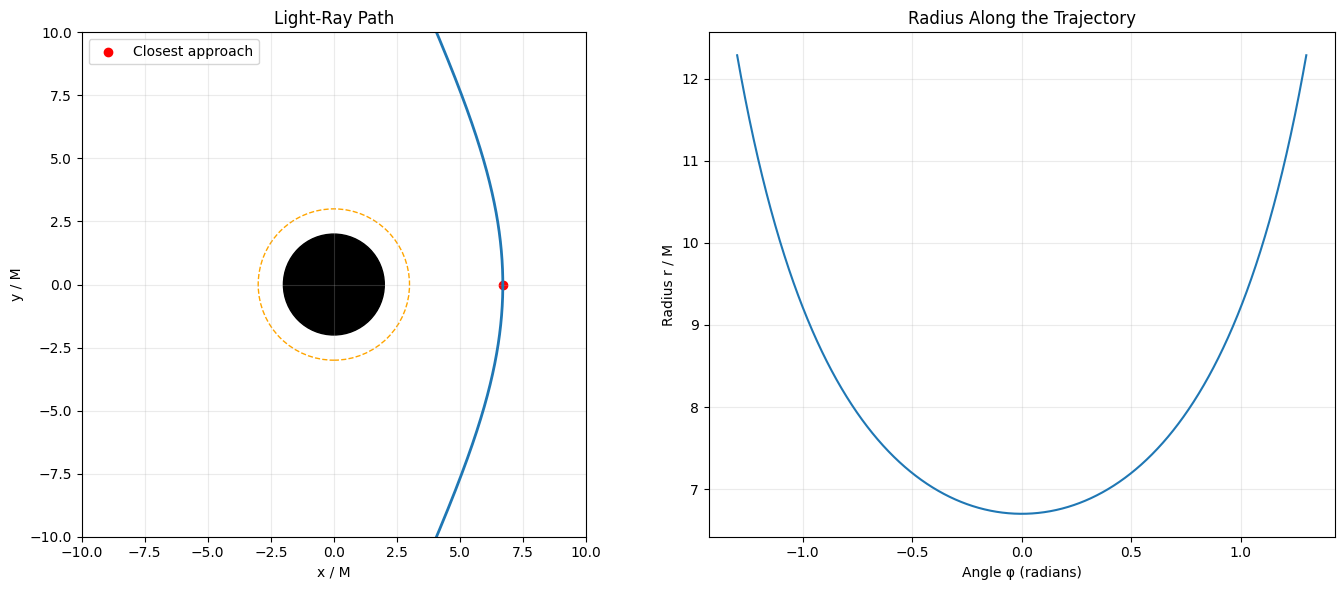

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: trajectory in the x-y plane
axes[0].plot(ray["x"], ray["y"], linewidth=2)
axes[0].scatter(
    ray["x"][len(ray["x"]) // 2],
    ray["y"][len(ray["y"]) // 2],
    color="red",
    label="Closest approach",
)
axes[0].add_patch(Circle((0, 0), 2 * M, color="black"))
axes[0].add_patch(
    Circle((0, 0), 3 * M, fill=False, linestyle="--", color="orange")
)
axes[0].set_xlim(-10, 10)
axes[0].set_ylim(-10, 10)
axes[0].set_aspect("equal")
axes[0].set_title("Light-Ray Path")
axes[0].set_xlabel("x / M")
axes[0].set_ylabel("y / M")
axes[0].grid(alpha=0.25)
axes[0].legend()

# Right: radius as a function of angle
axes[1].plot(ray["phi"], ray["radius"])
axes[1].set_title("Radius Along the Trajectory")
axes[1].set_xlabel("Angle φ (radians)")
axes[1].set_ylabel("Radius r / M")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# Black Hole Simulator — Light Ray Trajectories

## Objective
Explore how light rays travel near a black hole.

## Topics
- Position and direction vectors
- Straight-line motion
- Gravitational deflection
- Numerical integration
- Comparing ray trajectories


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

print("Light ray simulation initialized.")

Light ray simulation initialized.


#Define the black hole model


In [8]:
# Geometric units: G = c = M = 1
M = 1.0

# Important radii
r_s = 2 * M
r_ph = 3 * M

# Impact parameter of the light ray
b = 8.0

# Check whether the ray is above the critical impact parameter
b_critical = 3 * np.sqrt(3) * M

print("Event horizon radius:", r_s)
print("Photon sphere radius:", r_ph)
print("Critical impact parameter:", b_critical)
print("Chosen impact parameter:", b)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Critical impact parameter: 5.196152422706632
Chosen impact parameter: 8.0


Calculate the closest approach
In general relativity, the radius of closest approach \(r_0\) is related to the impact parameter by

In [9]:
def closest_approach_equation(r):
    return r**3 - b**2 * r + 2 * M * b**2


r_min = brentq(
    closest_approach_equation,
    3 * M + 1e-6,
    b
)

print("Closest approach radius:", r_min)

Closest approach radius: 6.700523482266461


#Define the light-ray equation

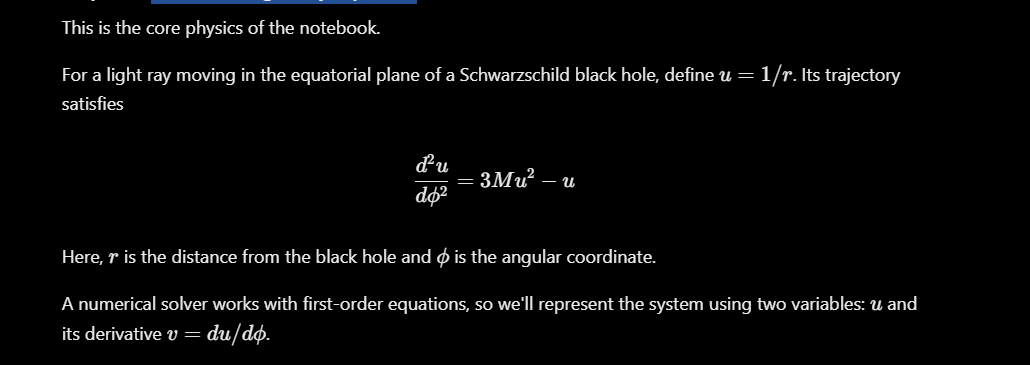

In [10]:
def light_ray_equations(phi, state):
    u, v = state

    du_dphi = v
    dv_dphi = 3 * M * u**2 - u

    return [du_dphi, dv_dphi]

#Numerically integrate the trajectory

In [11]:
initial_state = [1 / r_min, 0.0]

phi_start = 0.0
phi_end = 1.6

phi_values = np.linspace(phi_start, phi_end, 1000)

solution = solve_ivp(
    light_ray_equations,
    (phi_start, phi_end),
    initial_state,
    t_eval=phi_values,
    rtol=1e-9,
    atol=1e-11
)

u_values = solution.y[0]

# Convert inverse radius back into radius
r_values = 1 / u_values

print("Integration successful:", solution.success)
print("Number of trajectory points:", len(r_values))

Integration successful: True
Number of trajectory points: 1000


#Plot the curved ray

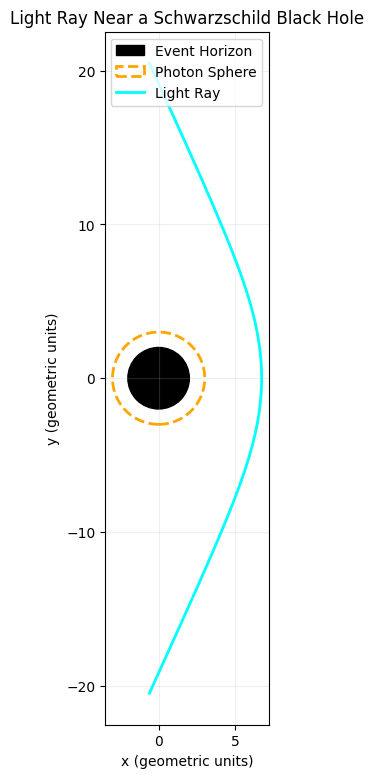

In [12]:
# Reflect the calculated path to obtain both sides
phi_full = np.concatenate((-phi_values[:0:-1], phi_values))
r_full = np.concatenate((r_values[:0:-1], r_values))

x_ray = r_full * np.cos(phi_full)
y_ray = r_full * np.sin(phi_full)

fig, ax = plt.subplots(figsize=(9, 9))

# Draw the event horizon
ax.add_patch(
    Circle((0, 0), r_s, color="black", label="Event Horizon")
)

# Draw the photon sphere
ax.add_patch(
    Circle(
        (0, 0),
        r_ph,
        fill=False,
        linestyle="--",
        linewidth=2,
        edgecolor="orange",
        label="Photon Sphere"
    )
)

# Draw the light ray
ax.plot(x_ray, y_ray, color="cyan", linewidth=2, label="Light Ray")

ax.set_aspect("equal")
ax.set_xlabel("x (geometric units)")
ax.set_ylabel("y (geometric units)")
ax.set_title("Light Ray Near a Schwarzschild Black Hole")
ax.grid(alpha=0.2)
ax.legend()

plt.show()